## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [3]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
Un centro de cómputo recibe diferentes tareas que deben ser procesadas por sus servidores.

Cada tarea tiene:

- Código.

- Nombre.

- Prioridad.

Las tareas con una prioridad numérica mayor deberán ser procesadas primero.

## 2) Requerimientos **[2 pts]**


**REQUERIMIENTOS  FUNCIONALES**

- RQF1: El sistema debe permitir ingresar una cantidad **n** de tareas

- RQF2: El sistema debe permitir ingresar codigo, nombre y prioridad de las tareas correspondientes.

- RQF3: El sistema debe alamacenar el valor numerico de las prioridades de cada tarea en un arreglo, manteniendo el orden en el que fueron 
ingresadas.

- RQF4: El sistema debe realizar un ordenamiento Max-heap, ubicando las tareas en orden prioritario, finalmente mostrarlas.

- RQF5: El sistema debe mostrar la tarea con mayor prioridad sin eliminarla.

- RQF6: El sistema debe retirar la tarea con mayor prioridad, mostrar la tarea procesada y actualizar el Max-heap.

- RQF7: El sistema debe permitir ingresar una nueva tarea, actualizando em max-heap para que se ubique en la pocision correspondiente.

- RQF8: El sistema debe permitir mostrar la lista HeapSort, mostrando la MaxHeap en orden ascendente.




**REQUERIMIENTOS NO FUNCIONALES**

- RQNF1: (Rendimiento)El sistema debe permitir manejar una cantidad **n** de tareas sin perder velocidad.

- RQNF2: (Escalabilidad)El sistema debe permitir ingresar  una nueva tarea (Codigo, nombre y prioridad) actualizando la lista original.

- RQNF3: (Mantenimiento)El sistema esta formado por funciones que cumplen un punto especifico, en caso de errores o actualizaciones se tiene mayor facilidad para manejar el sistema .

- RQNF4: (Usabilidad) El sistema debe mostrar mensajes claros para guiar al usuario al ingresar los datos de las tareas y presentar los resultados de forma comprensible.


## 3) Historias de usuario **[2 pts]**


Historia de usuario 1: Ingresar tareas

Como usuario, quiero ingresar una cantidad n de tareas con su código, nombre y prioridad, para registrarlas en el sistema y organizarlas según su prioridad.

CA:
- La cantidad de tareas debe ser un número entero positivo.
- Cada tarea debe tener un código, un nombre y una prioridad numérica.
- Si algún dato es inválido, se debe mostrar un mensaje informativo y solicitarlo nuevamente.
- Las prioridades se deben almacenar en un arreglo, manteniendo el orden en que se ingresaron.


Historia de usuario 2: Organizar las tareas en un Max-heap

Como usuario, quiero que el sistema organice las tareas en un Max-heap, para visualizarlas según su prioridad.

CA:
- El sistema debe ordenar las tareas mediante un Max-heap.
- Al finalizar, debe mostrar las tareas organizadas por prioridad.

Historia de usuario 3: Consultar y procesar la tarea prioritaria

Como usuario, quiero consultar o retirar la tarea con mayor prioridad, para saber cuál debe atenderse primero y procesarla.

CA:
- Al consultarla, el sistema debe mostrar la tarea con mayor prioridad sin eliminarla.
- Al retirar, debe mostrar la tarea procesada y actualizar el Max-heap.
- Si no hay tareas, debe mostrar un mensaje informativo.

Historia de usuario 4: Agregar una nueva tarea

Como usuario, quiero ingresar una nueva tarea con su código, nombre y prioridad, para agregarla al Max-heap en la posición correspondiente.

CA:
- El sistema debe solicitar los datos de la nueva tarea.
- La tarea debe agregarse al Max-heap según su prioridad.
- La lista original de tareas debe actualizarse.
- Si algún dato es inválido, debe mostrar un mensaje informativo y solicitarlo nuevamente.


Historia de usuario 5: Visualizar las tareas ordenadas

Como usuario, quiero visualizar las tareas mediante HeapSort, para consultarlas en orden ascendente de prioridad.

CA:
- El sistema debe mostrar las tareas en orden ascendente de prioridad.
- La visualización debe incluir el código, el nombre y la prioridad de cada tarea.

## 4) Diagramas de flujo **[5 pts]**

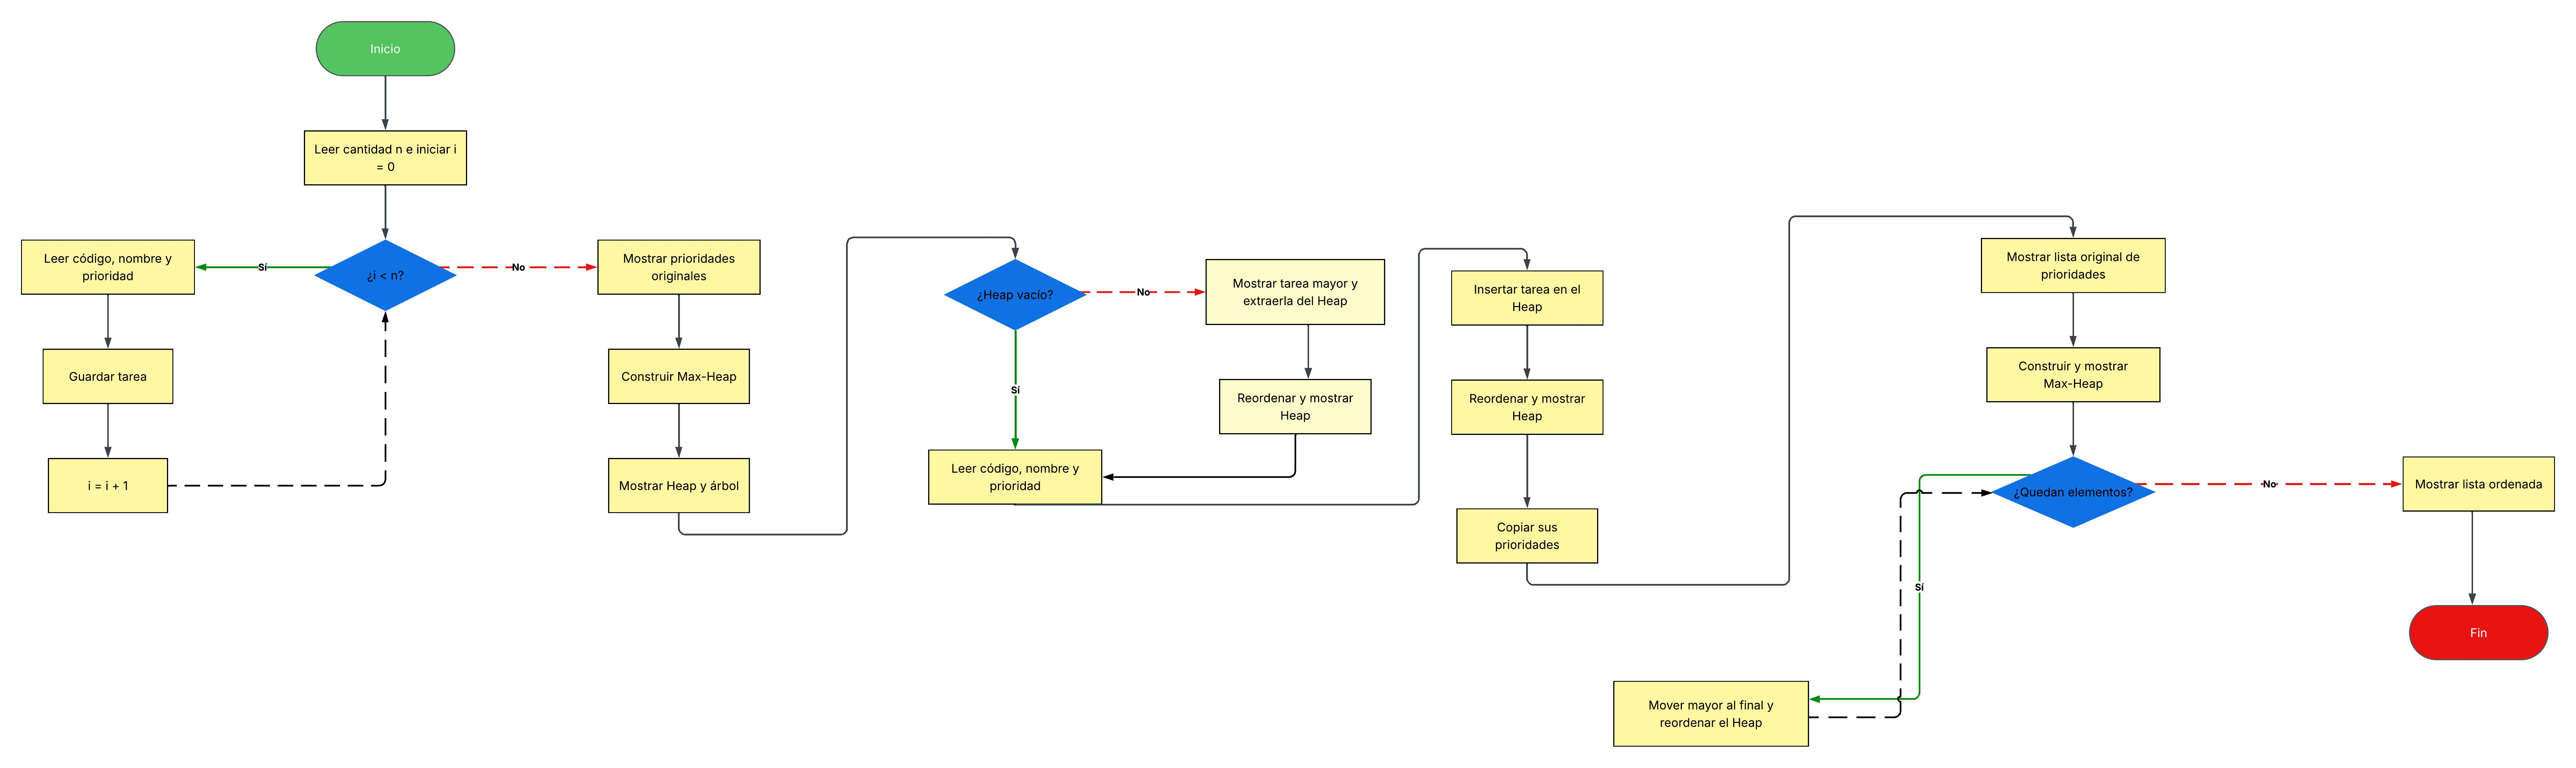

### 5) Análisis de complejidad **[15 pts]**

1. Heapsort: f(n) = n·log(n)
Primero armamos el montón de datos y después sacamos el número más grande uno por uno. Como son n números y cada vez que sacamos uno toca acomodar el montón (que cuesta log(n)), en total es n·log(n).

2. Build Max Heap: f(n) = n
Armar el montón parece que debería ser n·log(n), pero no. La mayoría de los datos están abajo y casi no hay que moverlos, así que al sumar todo el trabajo da solo n.

3. Heapify: f(n) = log(n)
Agarramos un número y lo vamos bajando por el árbol, comparándolo con sus hijos, hasta dejarlo en su lugar. Como el árbol no es muy alto, lo máximo que baja es log(n) pasos.

4. Priority Queue: f(n) = log(n)
Cuando metemos un dato nuevo, lo subimos por el árbol hasta donde le toca. Cuando sacamos el más importante, acomodamos el montón de nuevo. En ambos casos solo recorremos la altura del árbol, que es log(n).



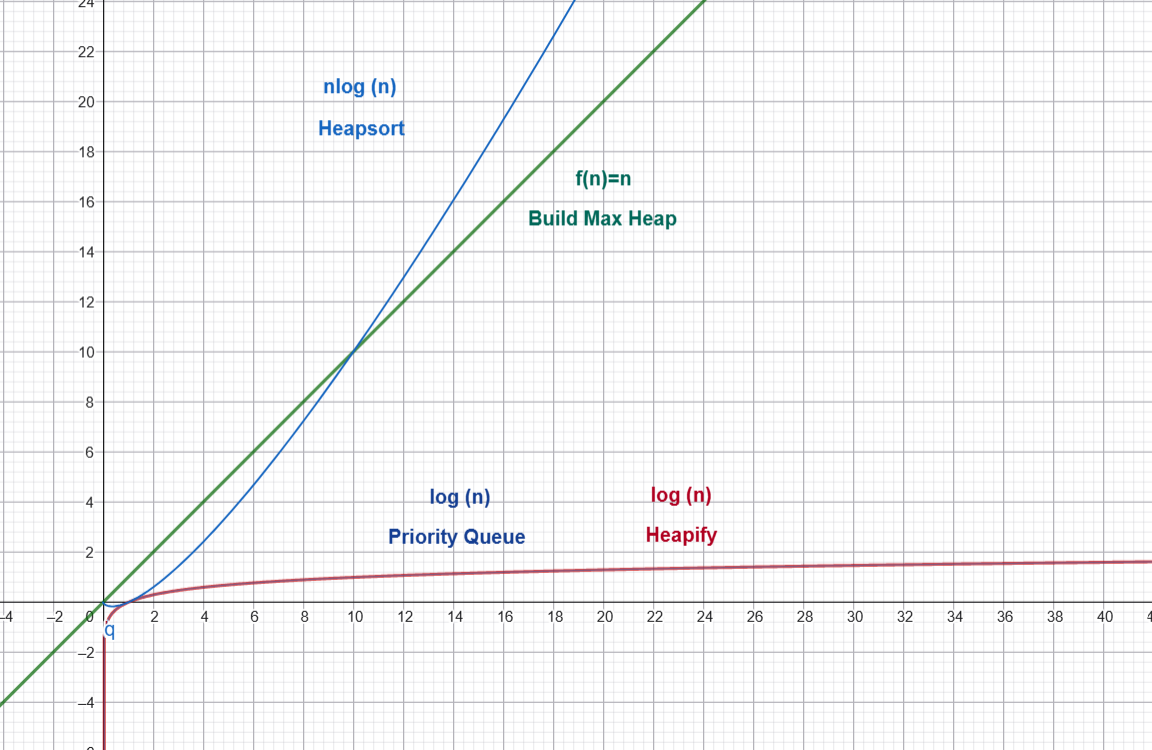

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [4]:
def heapify(t, n, i):
    mayor = i
    izq = 2 * i + 1
    der = 2 * i + 2
    if izq < n and t[izq][2] > t[mayor][2]:
        mayor = izq
    if der < n and t[der][2] > t[mayor][2]:
        mayor = der
    if mayor != i:
        t[i], t[mayor] = t[mayor], t[i]
        heapify(t, n, mayor)

def construir_heap(t):
    for i in range(len(t) // 2 - 1, -1, -1):
        heapify(t, len(t), i)

def extraer_max(t):
    if len(t) == 0:
        return None
    mayor = t[0]
    ultimo = t.pop()
    if len(t) > 0:
        t[0] = ultimo
        heapify(t, len(t), 0)
    return mayor

def insertar(t, tarea):
    t.append(tarea)
    i = len(t) - 1
    while i > 0:
        padre = (i - 1) // 2
        if t[i][2] <= t[padre][2]:
            break
        t[i], t[padre] = t[padre], t[i]
        i = padre

def heapify_num(a, n, i):
    mayor = i
    izq = 2 * i + 1
    der = 2 * i + 2
    if izq < n and a[izq] > a[mayor]:
        mayor = izq
    if der < n and a[der] > a[mayor]:
        mayor = der
    if mayor != i:
        a[i], a[mayor] = a[mayor], a[i]
        heapify_num(a, n, mayor)

n = int(input("Cantidad de tareas: "))
tareas = []
for i in range(n):
    print("Tarea", i + 1)
    cod = input("Codigo: ")
    nom = input("Nombre: ")
    pri = int(input("Prioridad: "))
    tareas.append([cod, nom, pri])

orig = [t[2] for t in tareas]
print("Lista original de prioridades:", orig)
construir_heap(tareas)
print("Max-Heap:", [t[2] for t in tareas])
print("Arbol del Heap:")
for i in range(len(tareas)):
    izq = 2 * i + 1
    der = 2 * i + 2
    if i == 0:
        print("Raiz:", tareas[i][0], tareas[i][2])
    else:
        print("Hijo de", tareas[(i - 1) // 2][0] + ":", tareas[i][0], tareas[i][2])

if len(tareas) > 0:
    print("Tarea de mayor prioridad:", tareas[0][0], "-", tareas[0][1], "Prioridad:", tareas[0][2])
    lista = extraer_max(tareas)
    print("Tarea procesada:", lista[0], "-", lista[1])
    print("Nuevo Heap:", [t[2] for t in tareas])

print("Ingrese una nueva tarea")
cod = input("Codigo: ")
nom = input("Nombre: ")
pri = int(input("Prioridad: "))
insertar(tareas, [cod, nom, pri])
print("Heap despues de insertar:", [t[2] for t in tareas])

val = [t[2] for t in tareas]
mh = val.copy()
for i in range(len(mh) // 2 - 1, -1, -1):
    heapify_num(mh, len(mh), i)
print("Lista original:", val)
print("Max-Heap:", mh)
for fin in range(len(mh) - 1, 0, -1):
    mh[0], mh[fin] = mh[fin], mh[0]
    heapify_num(mh, fin, 0)
print("Lista ordenada:", mh)


Tarea 1
Tarea 2
Tarea 3
Lista original de prioridades: [2, 3, 3]
Max-Heap: [3, 2, 3]
Arbol del Heap:
Raiz: algebra 3
Hijo de algebra: 201 2
Hijo de algebra: 203 3
Tarea de mayor prioridad: algebra - algebra Prioridad: 3
Tarea procesada: algebra - algebra
Nuevo Heap: [3, 2]
Ingrese una nueva tarea
Heap despues de insertar: [3, 2, 3]
Lista original: [3, 2, 3]
Max-Heap: [3, 2, 3]
Lista ordenada: [2, 3, 3]


## 7) Tests aplicados **[15 pts]**

### Prueba manual

**Entradas de las tareas:**

| Codigo | Nombre | Prioridad |
| --- | --- | ---: |
| T01 | Compilar proyecto | 8 |
| T02 | Generar backup | 4 |
| T03 | Renderizar video | 10 |
| T04 | Procesar correos | 3 |
| T05 | Ejecutar pruebas | 7 |
| T06 | Actualizar servidor | 6 |

**Tarea ingresada:** T07, Revisar reportes, prioridad 12.

**Resultados esperados:**

- Lista original: `[8, 4, 10, 3, 7, 6]`
- Max-Heap inicial: `[10, 7, 8, 3, 4, 6]`
- Tarea mayor: `T03 - Renderizar video`, prioridad `10`
- Tarea procesada: `T03 - Renderizar video`
- Heap despues de extraer: `[8, 7, 6, 3, 4]`
- Heap despues de insertar T07: `[12, 7, 8, 3, 4, 6]`
- Lista ordenada con HeapSort: `[3, 4, 6, 7, 8, 12]`
